# LEP-15 : Comparaison de l'espérance de vie selon le statut de développement

**Projet :** WHO Life Expectancy : Analyse des facteurs associés à l'espérance de vie  
**Sprint :** Sprint 3 : Analyse exploratoire et comparative  
**User Story :** LEP-15  
**Environnement :** Python ; Jupyter Notebook  
**Source des données :** Jeu de données fiabilisé du projet (`data/processed/life_expectancy_fiabilise.csv`)

---

## 1. Contexte et objectif

Dans le cadre du projet WHO Life Expectancy, cette analyse vise à comparer l'espérance de vie entre les pays classés selon leur statut de développement : `Developed` et `Developing`.

Après avoir identifié les pays présentant les espérances de vie les plus élevées et les plus faibles dans la User Story LEP-14, cette nouvelle analyse cherche à déterminer si des différences apparaissent également à l'échelle de ces deux groupes.

### Question analytique

**Quelles différences observe-t-on dans les niveaux et la distribution de l'espérance de vie entre les pays classés `Developed` et `Developing` sur la période 2000–2015 ?**

### Objectifs spécifiques

- Décrire la composition des deux groupes et leur couverture dans le jeu de données.
- Comparer les indicateurs de tendance centrale et de dispersion de l'espérance de vie.
- Visualiser les distributions afin d'identifier les différences et les éventuels chevauchements.
- Examiner l'évolution des niveaux moyens et des écarts entre les deux groupes de 2000 à 2015.
- Synthétiser les principaux constats et les limites de l'analyse.

### Périmètre méthodologique

L'analyse repose sur les données fiabilisées du projet, avec les valeurs d'espérance de vie harmonisées à partir de l'indicateur `SP.DYN.LE00.IN` de la Banque mondiale.

La variable `status`, issue du jeu de données initial, est utilisée pour distinguer les deux groupes. Cette classification sera considérée comme une catégorie fournie par le jeu de données, et non comme une mesure actualisée du niveau de développement des pays.

Les comparaisons seront descriptives et non causales. Les statistiques ne seront pas pondérées par la population des pays.

## 4. Chargement et vérification des données

In [1]:
# Bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

# Charger le jeu de données fiabilisé
df = pd.read_csv("../data/processed/life_expectancy_fiabilise.csv")

# Sélectionner les variables utiles à LEP-15
df_lep15 = df[["country", "year", "status", "life_expectancy"]].copy()

# Afficher les dimensions et un aperçu
print("Dimensions du jeu de données :", df_lep15.shape)

display(df_lep15.head())


Dimensions du jeu de données : (2938, 4)


,country,year,status,life_expectancy
0,Afghanistan,2015,Developing,62.270
1,Afghanistan,2014,Developing,62.260
2,Afghanistan,2013,Developing,62.188
3,Afghanistan,2012,Developing,61.735
4,Afghanistan,2011,Developing,61.250


## 4.2. Vérification de la structure et des catégories

In [3]:

# Vérifier les types des variables
print("Types des variables :")
display(df_lep15.dtypes)

# Examiner les catégories et leurs effectifs
print("\nEffectifs par statut de développement :")
display(
    df_lep15["status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="nombre_observations")
)

# Compter les pays distincts par statut
print("\nNombre de pays distincts par statut :")
display(
    df_lep15.groupby("status")["country"]
    .nunique()
    .reset_index(name="nombre_pays")
)


Types des variables :


country             object
year                 int64
status              object
life_expectancy    float64
dtype: object


Effectifs par statut de développement :


,status,nombre_observations
0,Developing,2426
1,Developed,512



Nombre de pays distincts par statut :


,status,nombre_pays
0,Developed,32
1,Developing,161


## 4.3. Vérification des valeurs manquantes

In [4]:

# Compter les valeurs manquantes par variable
print("Valeurs manquantes :")
display(df_lep15.isna().sum())

# Examiner la disponibilité de l'espérance de vie par groupe
disponibilite = (
    df_lep15.groupby("status")["life_expectancy"]
    .agg(
        nombre_observations="size",
        valeurs_disponibles="count"
    )
    .reset_index()
)

# Calculer les valeurs manquantes et leur proportion
disponibilite["valeurs_manquantes"] = (
    disponibilite["nombre_observations"]
    - disponibilite["valeurs_disponibles"]
)

disponibilite["taux_manquant_pct"] = (
    disponibilite["valeurs_manquantes"]
    / disponibilite["nombre_observations"]
    * 100
).round(2)

display(disponibilite)


Valeurs manquantes :


country            0
year               0
status             0
life_expectancy    2
dtype: int64

,status,nombre_observations,valeurs_disponibles,valeurs_manquantes,taux_manquant_pct
0,Developed,512,512,0,0.00
1,Developing,2426,2424,2,0.08


**Constat :** Le jeu de données contient 2 938 observations réparties entre 193 pays sur la période 2000–2015. Parmi ces pays, 32 sont classés `Developed`, représentant 512 observations, et 161 sont classés `Developing`, représentant 2 426 observations.

La répartition révèle un déséquilibre entre les deux groupes, les pays `Developing` constituant environ 83,4 % des pays étudiés.

Les variables `country`, `year` et `status` ne présentent aucune valeur manquante. La variable `life_expectancy` comporte seulement deux valeurs manquantes, toutes deux dans le groupe `Developing`, correspondant à un taux de 0,08 % pour ce groupe.

Les données sont suffisamment complètes pour réaliser une comparaison descriptive entre les deux catégories. Toutefois, les différences d'effectifs devront être prises en considération lors de l'interprétation des résultats.

**Décision :** Conserver les deux groupes et exclure uniquement les deux observations sans valeur d'espérance de vie des calculs statistiques. Aucune imputation supplémentaire n'est nécessaire pour cette analyse.

## 4.4. Comparaison des statistiques descriptives

### 4.4.1. Comparaison des indicateurs de tendance centrale et de dispersion.

In [5]:

# Conserver les observations avec une espérance de vie disponible
df_analyse = df_lep15.dropna(subset=["life_expectancy"]).copy()

# Calculer les statistiques descriptives par statut
statistiques = (
    df_analyse.groupby("status")["life_expectancy"]
    .agg(
        effectif="count",
        moyenne="mean",
        mediane="median",
        ecart_type="std",
        minimum="min",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        maximum="max"
    )
    .round(2)
)

# Calculer les étendues et les écarts interquartiles
statistiques["etendue"] = (
    statistiques["maximum"] - statistiques["minimum"]
).round(2)

statistiques["ecart_interquartile"] = (
    statistiques["q3"] - statistiques["q1"]
).round(2)

display(statistiques)


,effectif,moyenne,mediane,ecart_type,minimum,q1,q3,maximum,etendue,ecart_interquartile
status,,,,,,,,,,
Developed,512,78.46,79.25,3.20,70.31,76.56,80.95,83.79,13.48,4.39
Developing,2424,66.88,68.79,8.77,14.66,60.74,73.50,85.06,70.40,12.76


**Constat :** Sur la période 2000–2015, le groupe `Developed` présente une espérance de vie moyenne de 78,46 ans, contre 66,88 ans pour le groupe `Developing`, soit un écart de 11,58 ans. Les médianes confirment cette différence, avec respectivement 79,25 ans et 68,79 ans.

La dispersion est également différente entre les deux groupes. Les pays `Developed` présentent un écart-type de 3,20 ans et un écart interquartile de 4,39 ans, contre respectivement 8,77 ans et 12,76 ans pour les pays `Developing`.

Les valeurs extrêmes montrent cependant que les deux groupes ne sont pas entièrement séparés : le maximum du groupe `Developing` atteint 85,06 ans, contre 83,79 ans pour le groupe `Developed`. Le groupe `Developing` présente également une valeur minimale particulièrement faible de 14,66 ans, qui nécessite un examen spécifique.

Les observations appartenant au groupe `Developed` présentent globalement une espérance de vie plus élevée et une dispersion plus faible. À l'inverse, le groupe `Developing` se caractérise par des niveaux centraux inférieurs et une plus grande diversité des situations.

Ces différences constituent une association descriptive entre le statut de développement et l'espérance de vie. Elles ne permettent pas d'établir une relation causale. De plus, les résultats portent sur des observations pays-année non pondérées par la population.

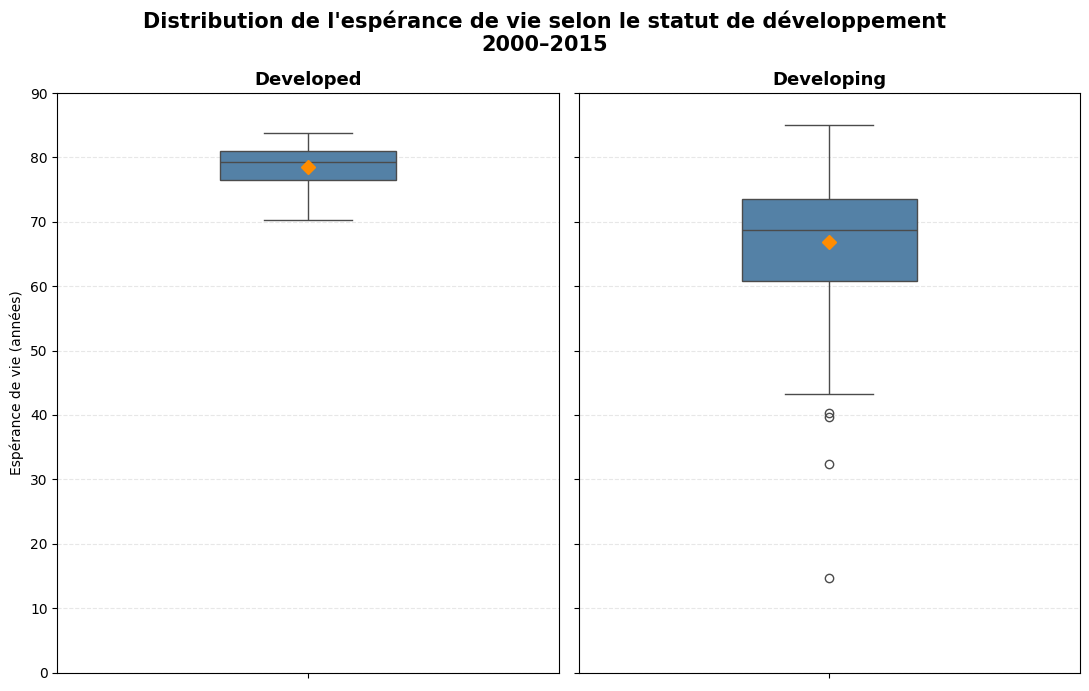

In [6]:
# Comparaison graphique avec des boxplots 

fig, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True)

groupes = ["Developed", "Developing"]

for ax, groupe in zip(axes, groupes):

    donnees = df_analyse.loc[
        df_analyse["status"] == groupe,
        "life_expectancy"
    ]

    sns.boxplot(
        y=donnees,
        ax=ax,
        color="steelblue",
        width=0.35,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "darkorange",
            "markeredgecolor": "darkorange",
            "markersize": 7
        }
    )

    ax.set_title(groupe, fontsize=13, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Espérance de vie (années)")
    ax.set_ylim(0, 90)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

fig.suptitle(
    "Distribution de l'espérance de vie selon le statut de développement\n2000–2015",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Constat :** Les boxplots mettent en évidence une différence importante entre les distributions d'espérance de vie des groupes `Developed` et `Developing`.

Le groupe `Developed` présente une distribution relativement concentrée autour d'une médiane de 79,25 ans, avec un écart interquartile de 4,39 ans. À l'inverse, le groupe `Developing` affiche une médiane de 68,79 ans et un écart interquartile de 12,76 ans, révélant une dispersion nettement plus importante.

Les intervalles interquartiles des deux groupes ne se chevauchent pas : le troisième quartile du groupe `Developing` (73,50 ans) demeure inférieur au premier quartile du groupe `Developed` (76,56 ans).

Le graphique révèle également plusieurs valeurs atypiques faibles dans le groupe `Developing`, dont une observation proche de 14,66 ans. Aucune valeur atypique n'est signalée par le boxplot du groupe `Developed`.

Ces résultats confirment que les observations appartenant au groupe `Developed` présentent généralement des espérances de vie plus élevées et plus homogènes.

Le groupe `Developing` se distingue par une plus grande diversité de situations, avec des pays atteignant des niveaux d'espérance de vie comparables à ceux du groupe `Developed`, tandis que d'autres présentent des valeurs nettement inférieures.

Cette comparaison décrit les distributions observées sur l'ensemble de la période 2000–2015. Elle ne permet pas, à elle seule, de déterminer comment les écarts ont évolué au fil des années.

In [7]:

# Identifier les cinq observations ayant
# les espérances de vie les plus faibles

display(
    df_analyse.nsmallest(5, "life_expectancy")[
        ["country", "year", "status", "life_expectancy"]
    ]
)


,country,year,status,life_expectancy
518,Central African Republic,2009,Developing,14.665
2381,Somalia,2011,Developing,32.453
2409,South Sudan,2015,Developing,39.757
513,Central African Republic,2014,Developing,40.265
1483,Lesotho,2006,Developing,43.182


**Constat :** L'examen des cinq observations présentant les espérances de vie les plus faibles montre qu'elles appartiennent toutes au groupe `Developing`.

La valeur minimale est observée en République centrafricaine en 2009 (14,665 ans), suivie de la Somalie en 2011 (32,453 ans) et du Soudan du Sud en 2015 (39,757 ans).

La comparaison avec les séries publiées à partir de l'indicateur `SP.DYN.LE00.IN` de la Banque mondiale confirme la présence de ces trois valeurs dans la source de référence.

Ces observations contribuent à la forte dispersion du groupe `Developing` et peuvent influencer particulièrement sa moyenne et son étendue.

Toutefois, certaines valeurs présentent des ruptures temporelles particulièrement importantes, notamment celle de la République centrafricaine en 2009. Leur présence dans une source officielle ne suffit donc pas à garantir leur plausibilité ou à expliquer leur origine.


### 4.4.2. Évolution annuelle de l'espérance de vie moyenne selon le statut de développement.

In [8]:

# Calculer l'espérance de vie moyenne par année et par statut
evolution_annuelle = (
    df_analyse
    .groupby(["year", "status"])["life_expectancy"]
    .mean()
    .unstack("status")
)

# Calculer l'écart annuel entre les deux groupes
evolution_annuelle["ecart"] = (
    evolution_annuelle["Developed"]
    - evolution_annuelle["Developing"]
)

# Présenter les résultats
display(evolution_annuelle.round(2))


status,Developed,Developing,ecart
year,,,
2000,76.54,64.24,12.30
2001,76.91,64.58,12.33
2002,77.06,64.90,12.16
2003,77.23,65.29,11.94
2004,77.68,65.61,12.07
2005,77.82,66.01,11.81
2006,78.06,66.39,11.67
2007,78.25,66.77,11.49
2008,78.54,67.11,11.43


**Constat :** Entre 2000 et 2015, l'espérance de vie moyenne augmente dans les deux groupes. Elle passe de 76,54 à 80,10 ans pour les pays `Developed`, soit une progression de 3,56 ans, et de 64,24 à 69,31 ans pour les pays `Developing`, soit une progression de 5,07 ans.

Cette progression plus importante du groupe `Developing` s'accompagne d'une réduction de l'écart entre les deux groupes, qui passe de 12,30 ans en 2000 à 10,79 ans en 2015.

Toutefois, cette diminution n'est pas parfaitement régulière. Certaines années présentent de légères augmentations de l'écart, notamment en 2004, 2009, 2011 et 2014.

**Interprétation :** Les résultats suggèrent un rapprochement progressif des niveaux moyens d'espérance de vie entre les deux catégories au cours de la période étudiée.

Cependant, malgré cette évolution favorable, les pays classés `Developing` présentent encore une espérance de vie moyenne inférieure de près de 11 ans à celle des pays `Developed` en 2015.

Cette évolution décrit les différences entre les moyennes nationales des deux groupes. Elle ne démontre pas que tous les pays ont progressé au même rythme et ne permet pas d'attribuer les écarts au statut de développement lui-même.

### 4.4.3. Visualisation de l'évolution annuelle

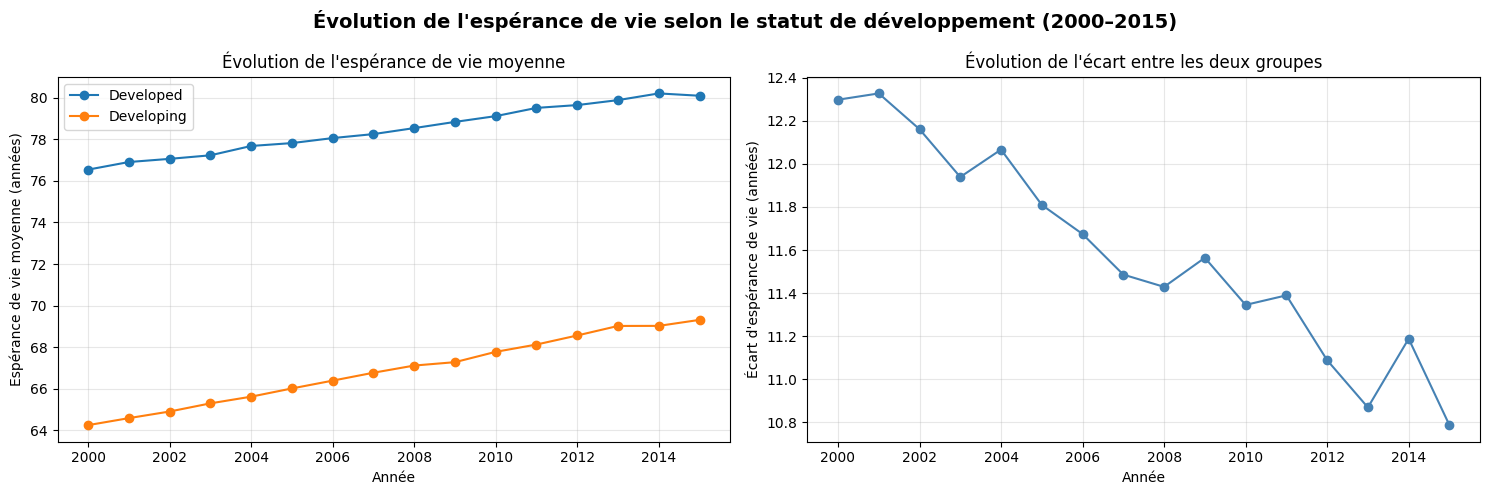

In [9]:

# Créer deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graphique 1 : évolution des moyennes
axes[0].plot(
    evolution_annuelle.index,
    evolution_annuelle["Developed"],
    marker="o",
    label="Developed"
)

axes[0].plot(
    evolution_annuelle.index,
    evolution_annuelle["Developing"],
    marker="o",
    label="Developing"
)

axes[0].set_title("Évolution de l'espérance de vie moyenne")
axes[0].set_xlabel("Année")
axes[0].set_ylabel("Espérance de vie moyenne (années)")
axes[0].set_xticks(range(2000, 2016, 2))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Graphique 2 : évolution de l'écart
axes[1].plot(
    evolution_annuelle.index,
    evolution_annuelle["ecart"],
    marker="o",
    color="steelblue"
)

axes[1].set_title("Évolution de l'écart entre les deux groupes")
axes[1].set_xlabel("Année")
axes[1].set_ylabel("Écart d'espérance de vie (années)")
axes[1].set_xticks(range(2000, 2016, 2))
axes[1].grid(alpha=0.3)

# Titre général
fig.suptitle(
    "Évolution de l'espérance de vie selon le statut de développement (2000–2015)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



**Constat :** Les courbes montrent une progression globale de l'espérance de vie moyenne dans les deux catégories de pays entre 2000 et 2015. Le groupe `Developed` conserve une moyenne supérieure sur l'ensemble de la période, mais sa progression est moins importante que celle du groupe `Developing`.

Le graphique des écarts confirme un rapprochement progressif des deux groupes, avec une diminution de la différence moyenne de 12,30 ans en 2000 à 10,79 ans en 2015.

Cette évolution n'est toutefois pas parfaitement régulière. Des augmentations ponctuelles de l'écart apparaissent certaines années, notamment en 2004, 2009, 2011 et 2014.

Les résultats suggèrent une réduction progressive des différences d'espérance de vie moyenne entre les deux groupes au cours de la période étudiée. Cette convergence reste néanmoins partielle, puisqu'un écart de près de 11 ans subsiste en 2015.

Il convient également de rappeler que ces courbes représentent des moyennes nationales non pondérées par la population. Elles ne permettent donc pas de conclure à une amélioration uniforme de l'espérance de vie dans tous les pays.

## 5. Analyse statistique pour la comparaison des groupes

### 5.1. Test t de Welch pour la comparaison des moyennes

#### 5.1.1. Objectif et hypothèses statistiques

L'analyse descriptive précédente a montré que les pays classés `Developed` présentent globalement une espérance de vie supérieure à celle des pays classés `Developing`.

Cette analyse statistique vise à examiner si la différence entre les moyennes des deux groupes est statistiquement significative.

**Question statistique :** L'espérance de vie moyenne des pays classés `Developed` diffère-t-elle de celle des pays classés `Developing` sur la période 2000–2015 ?

**Hypothèses :**

- **H₀ :** les moyennes d'espérance de vie des deux groupes sont égales (μDeveloped = μDeveloping).
- **H₁ :** les moyennes d'espérance de vie des deux groupes sont différentes (μDeveloped ≠ μDeveloping).

**Test retenu :** Test t de Welch pour deux échantillons indépendants, avec un seuil de significativité de 5 % (α = 0,05).

Le test de Welch permet de comparer deux moyennes sans supposer l'égalité des variances entre les groupes.

Afin de limiter le problème de dépendance lié aux observations répétées d'un même pays, le test sera appliqué aux moyennes nationales calculées sur la période 2000–2015, à raison d'une valeur par pays.

Seuls les pays disposant d'une série complète de 16 années avec une espérance de vie renseignée seront retenus pour cette comparaison.

In [10]:

from scipy.stats import ttest_ind

# Retenir les observations avec une espérance de vie disponible
df_test = df_lep15.dropna(subset=["life_expectancy"]).copy()

# Identifier les pays ayant 16 années distinctes renseignées
couverture = df_test.groupby("country")["year"].nunique()
pays_complets = couverture[couverture == 16].index

# Calculer une moyenne d'espérance de vie par pays
moyennes_pays = (
    df_test[df_test["country"].isin(pays_complets)]
    .groupby(["country", "status"], as_index=False)["life_expectancy"]
    .mean()
)

# Séparer les deux groupes
developed = moyennes_pays.loc[
    moyennes_pays["status"] == "Developed",
    "life_expectancy"
]

developing = moyennes_pays.loc[
    moyennes_pays["status"] == "Developing",
    "life_expectancy"
]

# Réaliser le test t de Welch
t_stat, p_value = ttest_ind(
    developed,
    developing,
    equal_var=False
)

# Présenter les résultats
print("Nombre de pays Developed :", len(developed))
print("Nombre de pays Developing :", len(developing))

print(f"\nMoyenne Developed : {developed.mean():.2f} ans")
print(f"Moyenne Developing : {developing.mean():.2f} ans")
print(f"Différence des moyennes : {developed.mean() - developing.mean():.2f} ans")

print(f"\nStatistique t : {t_stat:.4f}")
print(f"p-value : {p_value:.4g}")
print("Seuil de significativité : 0.05")


Nombre de pays Developed : 32
Nombre de pays Developing : 151

Moyenne Developed : 78.46 ans
Moyenne Developing : 66.87 ans
Différence des moyennes : 11.60 ans

Statistique t : 13.3001
p-value : 1.077e-26
Seuil de significativité : 0.05


Résultats et interprétation du test de Welch

**Résultats du test :**

- Pays retenus : 183, dont 32 `Developed` et 151 `Developing`.
- Moyenne du groupe `Developed` : 78,46 ans.
- Moyenne du groupe `Developing` : 66,87 ans.
- Différence des moyennes : 11,60 ans.
- Statistique du test : t = 13,3001.
- p-value : 1,077 × 10⁻²⁶.
- Seuil de significativité : α = 0,05.

**Constat :** Le test t de Welch met en évidence une différence statistiquement significative entre les moyennes d'espérance de vie des deux groupes (p < 0,05).

Les pays classés `Developed` présentent une espérance de vie moyenne supérieure de 11,60 ans à celle des pays classés `Developing`, sur la période 2000–2015.

L'hypothèse nulle d'égalité des moyennes est donc rejetée au seuil de 5 %.

Les résultats confirment que les différences observées dans l'analyse descriptive ne se limitent pas à une faible variation entre les moyennes des deux groupes. L'écart de 11,60 ans est également important sur le plan descriptif.

Le test repose sur une moyenne par pays, calculée à partir des 16 années d'observation, afin de limiter la dépendance liée aux mesures annuelles répétées.


### 5.2. Test du Khi-deux pour association entre le statut et une catégorie d'espérance de vie

#### 5.2.1. Objectif et hypothèses statistiques

Après avoir comparé les moyennes d'espérance de vie des deux groupes à l'aide du test t de Welch, cette analyse vise à examiner l'association entre le statut de développement et une catégorie d'espérance de vie.

Pour cette analyse, l'espérance de vie est répartie en deux catégories : moins de 70 ans et 70 ans ou plus. Ce seuil constitue un choix analytique et non une classification officielle.

L'année 2015 est retenue afin de disposer d'une seule observation par pays et d'éviter de traiter les mesures annuelles répétées comme indépendantes.

**Question statistique :** La répartition des pays entre les catégories d'espérance de vie est-elle associée à leur statut de développement en 2015 ?

**Hypothèses :**

- **H₀ :** le statut de développement et la catégorie d'espérance de vie sont indépendants.
- **H₁ :** il existe une association entre le statut de développement et la catégorie d'espérance de vie.

**Test retenu :** Khi-deux d'indépendance (χ²), avec un seuil de significativité de 5 % (α = 0,05).

Les conditions d'application du test seront examinées à partir des effectifs théoriques du tableau de contingence.

In [11]:

from scipy.stats import chi2_contingency

# Sélectionner les observations de 2015
df_chi2 = df_lep15.loc[
    (df_lep15["year"] == 2015)
    & (df_lep15["life_expectancy"].notna())
].copy()

# Créer deux catégories d'espérance de vie
df_chi2["categorie_esperance"] = pd.cut(
    df_chi2["life_expectancy"],
    bins=[-float("inf"), 70, float("inf")],
    labels=["Moins de 70 ans", "70 ans et plus"],
    right=False
)

# Construire le tableau de contingence
tableau_contingence = pd.crosstab(
    df_chi2["status"],
    df_chi2["categorie_esperance"]
)

print("Tableau de contingence :")
display(tableau_contingence)

# Calculer le test du Khi-deux
chi2, p_value_chi2, ddl, effectifs_attendus = (
    chi2_contingency(tableau_contingence, correction=False)
)

# Présenter les résultats du test
print(f"Statistique χ² : {chi2:.4f}")
print(f"Degrés de liberté : {ddl}")
print(f"p-value : {p_value_chi2:.4g}")
print("Seuil de significativité : 0.05")

# Vérifier les effectifs attendus
print("\nEffectifs théoriques :")
display(
    pd.DataFrame(
        effectifs_attendus,
        index=tableau_contingence.index,
        columns=tableau_contingence.columns
    ).round(2)
)

print(
    "Effectif théorique minimal :",
    round(effectifs_attendus.min(), 2)
)


Tableau de contingence :


categorie_esperance,Moins de 70 ans,70 ans et plus
status,,
Developed,0,32
Developing,69,82


Statistique χ² : 23.4730
Degrés de liberté : 1
p-value : 1.267e-06
Seuil de significativité : 0.05

Effectifs théoriques :


categorie_esperance,Moins de 70 ans,70 ans et plus
status,,
Developed,12.07,19.93
Developing,56.93,94.07


Effectif théorique minimal : 12.07


Décision statistique : puisque la p-value est inférieure à 0,05, nous rejetons H₀, l'hypothèse d'indépendance.

Nous disposons donc d'éléments statistiques indiquant une association entre le statut de développement et la catégorie d'espérance de vie.

#### Le Khi-deux indique qu'une association existe, mais il ne suffit pas à lui seul pour en apprécier l'intensité.

Nous allons donc calculer le V de Cramér, compris entre 0 et 1.

In [12]:

import numpy as np

# Nombre total de pays du tableau de contingence
n = tableau_contingence.to_numpy().sum()

# Nombre de lignes et de colonnes
lignes, colonnes = tableau_contingence.shape

# Calculer le V de Cramér
v_cramer = np.sqrt(
    chi2 / (n * min(lignes - 1, colonnes - 1))
)

# Afficher le résultat
print(f"Nombre de pays : {n}")
print(f"V de Cramér : {v_cramer:.4f}")


Nombre de pays : 183
V de Cramér : 0.3581


**Résultats du test :**

- Nombre de pays analysés : 183.
- Statistique du Khi-deux : χ²(1) = 23,473.
- p-value : 1,267 × 10⁻⁶.
- Effectif théorique minimal : 12,07.
- V de Cramér : 0,3581.
- Seuil de significativité : α = 0,05.

**Constat :** En 2015, les 32 pays classés `Developed` présentent une espérance de vie d'au moins 70 ans. Parmi les 151 pays classés `Developing`, 82 atteignent également ce seuil (54,3 %), tandis que 69 présentent une espérance de vie inférieure à 70 ans (45,7 %).

Le test du Khi-deux révèle une association statistiquement significative entre le statut de développement et la catégorie d'espérance de vie (χ²(1) = 23,473 ; p < 0,05). Les effectifs théoriques étant tous supérieurs à 5, les conditions usuelles relatives aux effectifs attendus sont satisfaites.

Le V de Cramér (0,3581) suggère une association d'intensité modérée selon les conventions usuelles.

La répartition des pays selon le seuil de 70 ans diffère significativement entre les deux groupes. Toutefois, plus de la moitié des pays classés `Developing` atteignent également ce seuil, ce qui souligne l'hétérogénéité de cette catégorie.

**Conclusion statistique :** L'hypothèse nulle d'indépendance est rejetée au seuil de 5 %. Les résultats mettent en évidence une association statistiquement significative, d'intensité modérée, entre le statut de développement et la catégorie d'espérance de vie en 2015.


## 6. Synthèse des résultats et conclusion

### 6.1. Principaux résultats

L'analyse comparative de l'espérance de vie selon le statut de développement, réalisée sur 193 pays entre 2000 et 2015, met en évidence trois principaux constats.

**Premièrement, les niveaux d'espérance de vie diffèrent sensiblement entre les deux groupes.** Sur l'ensemble de la période, les pays classés `Developed` présentent une espérance de vie moyenne de 78,46 ans, contre 66,88 ans pour les pays `Developing`, soit un écart de 11,58 ans. Les médianes confirment cette différence, avec respectivement 79,25 et 68,79 ans.

**Deuxièmement, la dispersion est nettement plus importante dans le groupe `Developing`.** Son écart-type atteint 8,77 ans, contre 3,20 ans pour le groupe `Developed`. La comparaison des intervalles interquartiles confirme cette hétérogénéité : 12,76 ans contre 4,39 ans.

Les distributions présentent néanmoins des chevauchements, ce qui indique que certains pays classés `Developing` atteignent des niveaux d'espérance de vie comparables à ceux du groupe `Developed`. Plusieurs valeurs atypiques particulièrement faibles ont également été relevées dans le groupe `Developing`, notamment en République centrafricaine en 2009 (14,665 ans).

**Troisièmement, les deux groupes enregistrent une progression globale de leur espérance de vie moyenne entre 2000 et 2015.** Cette progression atteint 3,56 ans pour les pays `Developed` et 5,07 ans pour les pays `Developing`.

L'écart annuel entre les moyennes des deux groupes diminue ainsi de 12,30 ans en 2000 à 10,79 ans en 2015, soit une réduction de 1,51 an. Cette diminution présente toutefois certaines fluctuations au cours de la période.

### 6.2. Réponse à la question analytique

Les résultats montrent que les pays classés `Developed` présentent globalement des niveaux d'espérance de vie plus élevés et une distribution plus homogène que les pays classés `Developing`.

Ces derniers se caractérisent par une plus grande diversité des situations nationales, avec des niveaux d'espérance de vie parfois comparables à ceux des pays `Developed`, mais également des observations nettement plus faibles.

L'analyse temporelle révèle néanmoins un rapprochement progressif des moyennes des deux groupes entre 2000 et 2015. Cette convergence demeure partielle, puisqu'un écart moyen de 10,79 ans subsiste en 2015.

### 6.3. Limites de l'analyse

Plusieurs limites doivent être prises en considération dans l'interprétation des résultats.

**Classification des pays :** La distinction `Developed` / `Developing` provient du jeu de données initial. Elle ne constitue pas une classification actualisée ni une mesure directe du niveau de développement économique ou social.

**Méthode de calcul :** Les statistiques sont calculées à partir d'observations pays-année, sans pondération par la population. Les pays disposant de davantage d'années d'observation contribuent donc davantage aux statistiques globales.

**Valeurs atypiques :** Certaines observations présentent des espérances de vie exceptionnellement faibles. Bien que conservées dans l'analyse, elles peuvent influencer les moyennes et les indicateurs de dispersion. Leur présence dans une source officielle ne dispense pas d'un examen de leur plausibilité.

**Portée des résultats :** L'analyse est descriptive. Elle met en évidence des différences et des évolutions entre les groupes, mais ne permet pas d'établir que le statut de développement explique directement les niveaux d'espérance de vie observés.

### 6.4. Conclusion

Cette User Story a permis de caractériser les différences d'espérance de vie entre les pays classés `Developed` et `Developing`, tant sur le plan des niveaux centraux que de la dispersion et de l'évolution temporelle.

Les résultats mettent en évidence des inégalités importantes entre les deux catégories, malgré une réduction progressive de leur écart moyen entre 2000 et 2015.

Ils soulignent également l'intérêt de considérer la diversité des situations au sein du groupe `Developing`, plutôt que de limiter l'interprétation à une opposition entre deux catégories.

Ces constats complètent les résultats de LEP-14, consacrés aux pays présentant les espérances de vie les plus élevées et les plus faibles, et contribuent à une compréhension plus globale des disparités internationales.

Ils constituent une base pour les analyses suivantes, notamment l'étude approfondie de l'évolution de l'espérance de vie au cours de la période 2000–2015 (**LEP-16**).